# Accessing CLMS HR Water, Snow and Ice products with the Sentinel Hub APIs

This Jupyter notebook provides a basic hands-on introduction to searching, retrieving and exploring High Resolution Water, Snow and Ice (HR-WSI) products. It focuses on the use of the **Sentinel Hub APIs** and is organised into two sections:
- A) Getting familiar with the Sentinel Hub APIs
- B) Exploring HR-WSI snow products

It follows the same path as the companion notebook [`odata_clms_hr_water_snow_ice.ipynb`](../../geo/odata_clms_hr_water_snow_ice.ipynb), which uses the OData API. The steps are numbered the same way, so the two can be read side by side. The difference is that OData returns whole product files to download and process locally, while Sentinel Hub processes the data on the server and returns only the pixels or statistics you asked for.

Users can first visit the [Copernicus Browser](https://browser.dataspace.copernicus.eu/) to explore and familiarise themselves with the available products.

**Contact**: https://land.copernicus.eu/en/contact-service-helpdesk

**Prerequisites**

Before starting, please complete the following steps:
- Create an account on the CDSE interface: https://dataspace.copernicus.eu/
- Create a set of Sentinel Hub OAuth credentials (a `client_id` and a `client_secret`) in the [CDSE Sentinel Hub dashboard](https://shapps.dataspace.copernicus.eu/dashboard/), under *User Settings*. The next section explains how to supply them to the notebook.

## Imports

All the libraries used in this notebook are imported here. They are included by default in the CDSE `sentinelhub` environment.

In [1]:
import json
import os
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from shapely.geometry import shape

from sentinelhub import (
    CRS,
    DataCollection,
    Geometry,
    MimeType,
    SentinelHubCatalog,
    SentinelHubRequest,
    SentinelHubSession,
    SentinelHubStatistical,
    SHConfig,
)

## Authentication

Sentinel Hub uses **OAuth 2.0 client credentials**: you create a `client_id` and a `client_secret` once, and the `sentinelhub` library exchanges them for short-lived access tokens on every call. There is no token to refresh by hand.

To create a pair, open the [CDSE Sentinel Hub dashboard](https://shapps.dataspace.copernicus.eu/dashboard/), go to *User Settings*, and create a new OAuth client. Copy the secret when it is shown, as it is not displayed again.

The cell below reads the credentials from the `SH_CLIENT_ID` and `SH_CLIENT_SECRET` environment variables and falls back to an interactive prompt if they are not set. To avoid typing them in every session, set the variables before launching Jupyter:

```bash
export SH_CLIENT_ID="your-client-id"
export SH_CLIENT_SECRET="your-client-secret"
```

If you use Sentinel Hub regularly, you can instead save the credentials once with `SHConfig.save()` and let the library pick them up automatically. See the [sentinelhub-py configuration documentation](https://sentinelhub-py.readthedocs.io/en/latest/configure.html).

The last line requests a token immediately. This is not strictly necessary, as the library would fetch one on the first data request anyway, but doing it here means a wrong `client_id` or `client_secret` fails at this cell with `UnauthorizedClientError` rather than further down the notebook.

In [2]:
config = SHConfig()

# CDSE service endpoints. These differ from the sentinelhub-py defaults.
config.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
config.sh_base_url = "https://sh.dataspace.copernicus.eu"

# Environment variables first, interactive prompt as a fallback.
config.sh_client_id = os.environ.get("SH_CLIENT_ID") or getpass(
    "Sentinel Hub client id: "
)
config.sh_client_secret = os.environ.get("SH_CLIENT_SECRET") or getpass(
    "Sentinel Hub client secret: "
)

# Ask for a token straight away, so that wrong credentials fail here with a clear
# message rather than several cells later on a data request.
SentinelHubSession(config=config)
print(f"Authenticated against {config.sh_base_url}")

Authenticated against https://sh.dataspace.copernicus.eu


# A. Discover the Sentinel Hub APIs to access the HR-WSI products

In this section, we will:
1. Explore the available snow datasets
2. Set the search parameters and configure the request
3. Execute the request
4. Retrieve the data
5. Modify the request to add a cloud percentage filter

## 1. The CLMS datasets on Sentinel Hub
The different CLMS collection datasets are listed here: https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Data/CLMS.html  
More information on the CLMS HR-WSI snow portfolio: https://land.copernicus.eu/en/products/snow

On Sentinel Hub, each CLMS product is a **collection** with its own ID. That ID is what you pass to the API when requesting data.

The HR-WSI snow datasets are:

In [3]:
### Snow cover
fsc = {
    "short_name": "FSC",
    "full_name": "Fractional Snow Cover",
    "collection_id": "2bb9974a-0eb8-484d-adf1-20cc307021b6",
    "resolution_m": 20,
}
gfsc = {
    "short_name": "GFSC",
    "full_name": "Gap-filled Fractional Snow Cover",
    "collection_id": "0b5265f5-3664-44c2-96ab-e91aba67b0c3",
    "resolution_m": 60,
}

### Snow state
sws = {
    "short_name": "SWS",
    "full_name": "SAR Wet Snow in high mountain areas",
    "collection_id": "41fc21f0-b657-4346-a4ab-aafc8cc636f2",
    "resolution_m": 60,
}
wds = {
    "short_name": "WDS",
    "full_name": "Wet/Dry Snow",
    "collection_id": "e52773f2-d35d-492d-8144-371a9e741212",
    "resolution_m": 60,
}

### Snow phenology
sps2 = {
    "short_name": "SPS2",
    "full_name": "Snow Phenology based on Sentinel-2",
    "collection_id": "0316f5d4-1320-41a1-994e-d756902efa9f",
    "resolution_m": 20,
}
sps1s2 = {
    "short_name": "SPS1S2",
    "full_name": "Snow Phenology based on Sentinel-1 & 2 - in high mountain areas",
    "collection_id": "1896152f-75d8-4daf-9db9-987773559a2c",
    "resolution_m": 60,
}

### Cloud cover
cc = {
    "short_name": "CC",
    "full_name": "Cloud classification Sentinel-2",
    "collection_id": "64d015da-e225-48d8-9643-30a453657beb",
    "resolution_m": 20,
}

HRWSI_snow_collection = {
    "FSC": fsc,
    "GFSC": gfsc,
    "SWS": sws,
    "WDS": wds,
    "SPS2": sps2,
    "SPS1S2": sps1s2,
    "CC": cc,
}

pd.DataFrame(HRWSI_snow_collection).T[["full_name", "resolution_m", "collection_id"]]

,full_name,resolution_m,collection_id
FSC,Fractional Snow Cover,20,2bb9974a-0eb8-484d-adf1-20cc307021b6
GFSC,Gap-filled Fractional Snow Cover,60,0b5265f5-3664-44c2-96ab-e91aba67b0c3
SWS,SAR Wet Snow in high mountain areas,60,41fc21f0-b657-4346-a4ab-aafc8cc636f2
WDS,Wet/Dry Snow,60,e52773f2-d35d-492d-8144-371a9e741212
SPS2,Snow Phenology based on Sentinel-2,20,0316f5d4-1320-41a1-994e-d756902efa9f
SPS1S2,Snow Phenology based on Sentinel-1 & 2 - in hi...,60,1896152f-75d8-4daf-9db9-987773559a2c
CC,Cloud classification Sentinel-2,20,64d015da-e225-48d8-9643-30a453657beb


## 2. Set the search parameters and configure the request

In [4]:
# Define which product will be requested
collection = DataCollection.define_byoc(
    HRWSI_snow_collection["FSC"]["collection_id"], name="HRWSI_FSC"
)

# Define start and end date of interest
start_date = "2026-01-01"
end_date = "2026-05-18"

# Define an area of interest (you can rely on the "create an area of interest" tool in the
# upper-right panel of the Copernicus Browser). Sentinel Hub accepts either a bounding box
# or a polygon.
aoi_wgs84 = shape(
    {
        "type": "Polygon",
        "coordinates": [
            [
                [6.726379, 45.792425],
                [6.726379, 45.519820],
                [7.792053, 45.531365],
                [7.789307, 45.960697],
                [6.726379, 45.792425],
            ]
        ],
    }
)

# Work in EPSG:3035 (LAEA Europe), whose units are metres, so that the "resolution"
# argument used later means metres on the ground.
aoi = Geometry(aoi_wgs84, crs=CRS.WGS84).transform(CRS("3035"))

xmin, ymin, xmax, ymax = aoi.bbox
print(f"Collection:  {collection.name}")
print(f"Time range:  {start_date} to {end_date}")
print(f"AOI extent:  {(xmax - xmin) / 1000:.0f} x {(ymax - ymin) / 1000:.0f} km")

Collection:  HRWSI_FSC
Time range:  2026-01-01 to 2026-05-18
AOI extent:  84 x 48 km


## 3. Execute the request

The **Catalog API** lists which products exist for a collection, over an area, in a time range.

The results are individual **tiles**, so several entries usually share a date: a large area is covered by more than one tile.

In [5]:
catalog = SentinelHubCatalog(config=config)


# Function to query the catalogue through the API
def execute_request(data_collection, geometry, time_interval):
    """Search the Sentinel Hub Catalog and return the results as a DataFrame."""
    search = catalog.search(
        data_collection,
        geometry=geometry,
        time=time_interval,
        fields={"include": ["id", "properties.datetime"], "exclude": []},
    )
    results = [
        {
            "Id": item["id"],
            "Date": pd.to_datetime(item["properties"]["datetime"]).date(),
        }
        for item in search
    ]
    print(f"Number of results: {len(results)}")
    return pd.DataFrame(results)

In [6]:
# Execute the request
results = execute_request(collection, aoi, (start_date, end_date))

# Display the first lines of the result
results.head(5)

Number of results: 170


,Id,Date
0,1fb636c0-b084-4625-b51a-d0dfe498ac9f,2026-05-12
1,a25857fe-f4a7-4b97-b40f-7bcbc5cd94df,2026-05-12
2,26c70277-34d8-44df-920e-ba29870bfb5e,2026-05-12
3,f4b2b75d-af10-40ba-8e4b-ca2c8062f9a4,2026-05-12
4,d7912a0f-2245-4149-bda4-f7f2014efa1d,2026-05-08


In [7]:
# The tiles group into a smaller number of distinct acquisition dates.
available_dates = sorted(results["Date"].unique())
print(f"{len(results)} tiles on {len(available_dates)} distinct dates")
print(f"First: {available_dates[0]}   Last: {available_dates[-1]}")

170 tiles on 38 distinct dates
First: 2026-01-01   Last: 2026-05-12


## 4. Retrieve the output data

The **Process API** applies your area, time range and resolution on the server and returns the resulting array directly. Nothing is written to disk.

A Process API request needs an **evalscript**: a short JavaScript function that Sentinel Hub runs **once per pixel, server-side**. `setup()` declares which bands go in and what comes out, and `evaluatePixel()` computes the output values.

`dataMask` is a Sentinel Hub convention: `1` where valid data exists, `0` elsewhere. It matters here because a snow fraction of `0` means "no snow", not "nothing observed".

### Retrieve **a single product**

The FSC product carries several layers. Here we ask for `FSCTOC` (Fractional Snow Cover at Top Of Canopy), the main snow fraction layer.

Note that a catalogue result means a tile **intersects** your area, not that it covers all of it: Sentinel-2 flies in swaths, so on some dates only a corner of the area is observed. We use a date with good coverage here.

FSC has a native resolution of 20 m. Over this area that would be about 4150 x 2450 pixels, which exceeds the Process API limit of 2500 pixels per side, so we request 60 m instead. The server resamples for you, so you are never tied to the product's native grid.

In [8]:
# Keep the evalscript minimal: return the raw value plus the mask, and interpret the
# result in Python. That keeps the product's special values visible.
fsc_evalscript = """
//VERSION=3
function setup() {
  return {
    input: ["FSCTOC", "dataMask"],
    output: { bands: 2, sampleType: "UINT8" }
  };
}
function evaluatePixel(sample) {
  return [sample.FSCTOC, sample.dataMask];
}
"""


def fetch(data_collection, evalscript, geometry, date, resolution, end_date=None):
    """Run one Process API request and return the resulting array.

    The last axis holds the output bands, in the order the evalscript returns them.
    Pass `end_date` to cover a range rather than a single date.
    """
    return SentinelHubRequest(
        evalscript=evalscript,
        input_data=[
            SentinelHubRequest.input_data(
                data_collection=data_collection, time_interval=(date, end_date or date)
            )
        ],
        responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
        geometry=geometry,
        resolution=(resolution, resolution),
        config=config,
    ).get_data()[0]


single_date = "2026-01-05"

response = fetch(collection, fsc_evalscript, aoi, single_date, 60)
fsc, fsc_mask = response[..., 0], response[..., 1]

print(f"FSC on {single_date}")
print(f"  raster shape: {fsc.shape[0]} x {fsc.shape[1]} px at 60 m")
print(f"  valid pixels: {int((fsc_mask > 0).sum()):,}")

FSC on 2026-01-05
  raster shape: 794 x 1408 px at 60 m
  valid pixels: 900,327


### Reading the values

Like most HR-WSI layers, `FSCTOC` mixes a measurement with status codes, so the array has to be interpreted before it is plotted:

| Value | Meaning |
|---|---|
| `0`-`100` | snow fraction in percent |
| `205` | cloud or cloud shadow |
| `210` | inland water |
| `255` | no data |

The colours used below are the official CLMS ones: a dark blue to white ramp for the snow fraction, grey for cloud and blue for water.

In [9]:
# The official CLMS colours for the snow-fraction layers, taken from the collection's
# CLMS colour ramp: 0 -> [8, 51, 112], 100 -> [255, 255, 255], 205 (cloud) ->
# [123, 123, 123], 210 (water) -> [100, 100, 215]. The 0-100 ramp is linear, so two
# stops reproduce the official table exactly.
SNOW_RAMP = LinearSegmentedColormap.from_list(
    "clms_snow", [(8 / 255, 51 / 255, 112 / 255), (1.0, 1.0, 1.0)]
)
CLOUD_COLOR = (123 / 255, 123 / 255, 123 / 255)
WATER_COLOR = (100 / 255, 100 / 255, 215 / 255)


def snow_fraction_rgb(values, mask):
    """Turn a snow-fraction band into an RGBA image using the official CLMS colours."""
    rgb = np.zeros(values.shape + (4,))
    measured = (values <= 100) & (mask > 0)
    rgb[measured] = SNOW_RAMP(values[measured] / 100.0)
    rgb[(values == 205) & (mask > 0)] = (*CLOUD_COLOR, 1.0)
    rgb[(values == 210) & (mask > 0)] = (*WATER_COLOR, 1.0)
    return rgb


def add_snow_legend(ax):
    """Add a snow-fraction colourbar plus swatches for the status codes."""
    scalar_map = plt.cm.ScalarMappable(
        cmap=SNOW_RAMP, norm=plt.Normalize(vmin=0, vmax=100)
    )
    bar = ax.figure.colorbar(scalar_map, ax=ax, shrink=0.6, pad=0.02)
    bar.set_label("Snow fraction (%)")
    ax.legend(
        handles=[
            plt.Line2D(
                [], [], marker="s", linestyle="", color=CLOUD_COLOR, label="cloud"
            ),
            plt.Line2D(
                [], [], marker="s", linestyle="", color=WATER_COLOR, label="water"
            ),
        ],
        loc="lower right",
        frameon=True,
    )

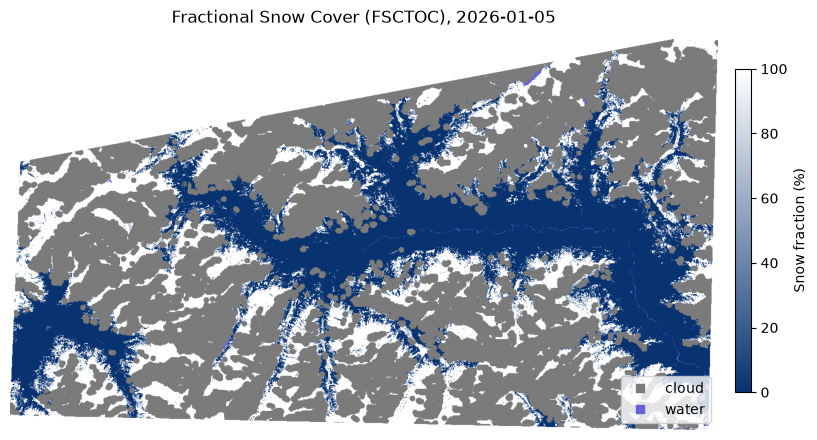

In [10]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.imshow(snow_fraction_rgb(fsc, fsc_mask), extent=(xmin, xmax, ymin, ymax))
ax.set_title(f"Fractional Snow Cover (FSCTOC), {single_date}")
ax.set_axis_off()
add_snow_legend(ax)
plt.show()

### Retrieve **several products**

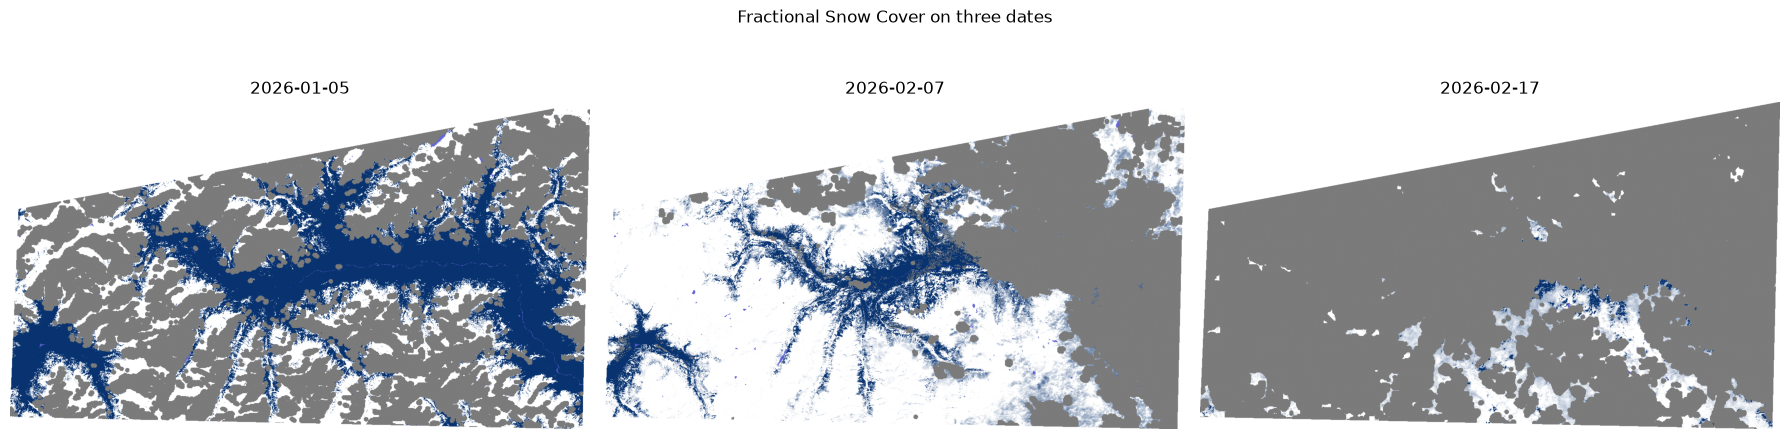

In [11]:
# The same request, repeated over different dates.
selected_dates = ["2026-01-05", "2026-02-07", "2026-02-17"]

fig, axes = plt.subplots(1, len(selected_dates), figsize=(6 * len(selected_dates), 5))
for ax, date in zip(axes, selected_dates):
    response = fetch(collection, fsc_evalscript, aoi, date, 60)
    ax.imshow(
        snow_fraction_rgb(response[..., 0], response[..., 1]),
        extent=(xmin, xmax, ymin, ymax),
    )
    ax.set_title(date)
    ax.set_axis_off()

fig.suptitle("Fractional Snow Cover on three dates")
plt.tight_layout()
plt.show()

## 5. Modify the request to add a cloud percentage filter

HR-WSI products which are based on satellite optical observations are impacted by the cloud cover (for snow products: FSC, GFSC, WDS). One can apply a filter to only keep the dates with a high proportion of usable data.

The **Statistical API** computes the cloud fraction over your own area and returns numbers rather than pixels, so one request covers the whole period.

In [12]:
# You can apply this cloud cover filter using any threshold you like.
CLOUD_COVER_MAX = 50.0

cloud_evalscript = """
//VERSION=3
function setup() {
  return {
    input: [{ bands: ["FSCTOC", "dataMask"] }],
    output: [
      { id: "cloud", bands: 1, sampleType: "FLOAT32" },
      { id: "dataMask", bands: 1 }
    ],
    mosaicking: "SIMPLE"
  };
}
function evaluatePixel(sample) {
  // Count a pixel as valid unless it is outside the AOI or flagged as no data.
  var valid = sample.dataMask === 1 && sample.FSCTOC !== 255;
  return {
    cloud: [sample.FSCTOC === 205 ? 1 : 0],
    dataMask: [valid ? 1 : 0]
  };
}
"""

cloud_stats = SentinelHubStatistical(
    aggregation=SentinelHubStatistical.aggregation(
        evalscript=cloud_evalscript,
        time_interval=(start_date, end_date),
        aggregation_interval="P1D",
        resolution=(120, 120),  # coarser: we want one number per date, not a map
    ),
    input_data=[SentinelHubStatistical.input_data(collection)],
    geometry=aoi,
    config=config,
).get_data()[0]

rows = []
for interval in cloud_stats["data"]:
    stats = interval["outputs"]["cloud"]["bands"]["B0"]["stats"]
    if stats["sampleCount"] == stats.get("noDataCount", 0):
        continue  # nothing observed that day
    rows.append(
        {
            "Date": pd.to_datetime(interval["interval"]["from"]).date(),
            "cloud_pct": round(100 * stats["mean"], 1),
        }
    )

cloud_df = pd.DataFrame(rows).sort_values("Date").reset_index(drop=True)
results_cloud = cloud_df[cloud_df["cloud_pct"] <= CLOUD_COVER_MAX]

print(f"{len(cloud_df)} dates with observations")
print(
    f"{len(results_cloud)} dates with cloud cover <= {CLOUD_COVER_MAX} % over the AOI"
)
results_cloud.head(5)

30 dates with observations
19 dates with cloud cover <= 50.0 % over the AOI


,Date,cloud_pct
2,2026-01-12,30.2
5,2026-01-25,31.3
8,2026-02-07,34.5
9,2026-02-14,0.0
11,2026-02-24,20.2


# B. Explore the HR-WSI snow data

**Prerequisite:**  
A vector file describing the area to study. Here we use a GeoJSON containing a single river basin, which ships with this notebook in the `data` folder.

In this section, we will:
1. Read the basin geometry
2. Set the search parameters and configure the request, to match the selected water basin's extent
3. Execute the request and retrieve the data
4. Display the product, cropped to the basin boundaries
5. Filter observations with quality layer information: sensor type
6. Explore yearly snow products

## 1. Read the basin geometry

We use the Swiss part of the **Rhine** river basin district (`CH10`), an alpine catchment of about 27,800 km². The polygon comes from the EEA's WISE Water Framework Directive dataset of river basin districts and sub-units, from which the single feature has been extracted and simplified so that it is small enough to ship alongside the notebook.

Any polygon works here. If you want to study a different area, replace this file with your own GeoJSON and the rest of the notebook runs unchanged.

In [13]:
# Define the basin file
basin_file = Path("../data/rhine_basin_ch.geojson")

# Read the basin geometry
print(f"Reading basin geometry from {basin_file}...")
basin_geojson = json.loads(basin_file.read_text(encoding="utf-8"))

basin_name = basin_geojson["properties"]["name"]
my_basin = Geometry(shape(basin_geojson["geometry"]), crs=CRS.WGS84).transform(
    CRS("3035")
)

bxmin, bymin, bxmax, bymax = my_basin.bbox
print(f"Successfully selected basin: {basin_name}")
print(f"  area:         {basin_geojson['properties']['areaKm2']:,.0f} km2")
print(f"  bounding box: {(bxmax - bxmin) / 1000:.0f} x {(bymax - bymin) / 1000:.0f} km")
print(f"  source:       {basin_geojson['properties']['source']}")

Reading basin geometry from ../data/rhine_basin_ch.geojson...
Successfully selected basin: Rhine river basin district (Switzerland)
  area:         27,814 km2
  bounding box: 309 x 161 km
  source:       EEA WISE WFD River Basin Districts and Sub-Units (RBDSU f1v4), EPSG:4326


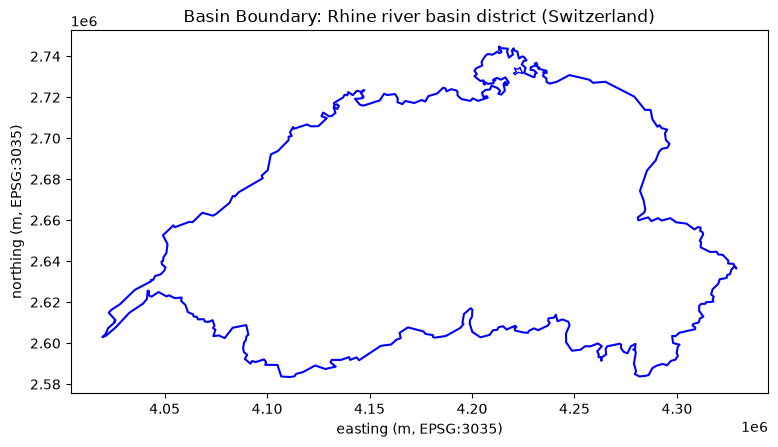

In [14]:
# Plot our basin outline as a reference
fig, ax = plt.subplots(figsize=(9, 5))
bx, by = my_basin.geometry.exterior.xy
ax.plot(bx, by, color="blue", linewidth=1.5)
for interior in my_basin.geometry.interiors:
    ix, iy = interior.xy
    ax.plot(ix, iy, color="blue", linewidth=1.0)
ax.set_aspect("equal")
ax.set_title(f"Basin Boundary: {basin_name}")
ax.set_xlabel("easting (m, EPSG:3035)")
ax.set_ylabel("northing (m, EPSG:3035)")
plt.show()

## 2. Set the search parameters and configure the request, to match the selected water basin's extent

Instead of the generic polygon used in section A, we can pass the basin geometry directly to the Sentinel Hub requests to work with HR-WSI products over our chosen Alpine river basin.

We switch to **GFSC** (Gap-filled Fractional Snow Cover) here. It merges Sentinel-1 and Sentinel-2 observations from the previous seven days, so it has far fewer cloud gaps than the raw FSC product, which makes it a better choice for a basin-wide view.

GFSC has three bands:

| Band | Meaning |
|---|---|
| `GF` | Snow fraction in %. `0`-`100` = snow fraction, `205` = cloud or cloud shadow, `210` = inland water |
| `GF_QA` | Quality of the `GF` value: `0` high, `1` medium, `2` low, `3` minimal |
| `QAFLAGS` | Bitmask of per-pixel quality flags, including which sensor the value came from |

In [15]:
# Set up the parameters
gfsc_collection = DataCollection.define_byoc(
    HRWSI_snow_collection["GFSC"]["collection_id"], name="HRWSI_GFSC"
)

product_date = "2026-04-23"
CLOUD_COVER_MAX = 30.0

# The basin spans roughly 305 x 163 km. At GFSC's native 60 m that would be about
# 5089 x 2719 pixels, above the Process API limit of 2500 pixels per side, so we request
# the basin-wide view at a coarser resolution.
BASIN_RES = 150

print(f"Collection:   {gfsc_collection.name}")
print(f"Product date: {product_date}")
print(f"Resolution:   {BASIN_RES} m")

Collection:   HRWSI_GFSC
Product date: 2026-04-23
Resolution:   150 m


## 3. Execute the request and retrieve the output data

First check what is available over the basin, then fetch it.

In [16]:
# Execute the request
print("Executing query for products intersecting our selected basin...")
basin_results = execute_request(gfsc_collection, my_basin, (product_date, product_date))

# Apply the cloud filter, the same way as in section A.5 but over the basin.
product_date_end = str((pd.Timestamp(product_date) + pd.Timedelta(days=1)).date())

basin_cloud_evalscript = """
//VERSION=3
function setup() {
  return {
    input: [{ bands: ["GF", "dataMask"] }],
    output: [
      { id: "cloud", bands: 1, sampleType: "FLOAT32" },
      { id: "dataMask", bands: 1 }
    ],
    mosaicking: "SIMPLE"
  };
}
function evaluatePixel(sample) {
  var valid = sample.dataMask === 1 && sample.GF !== 255;
  return {
    cloud: [sample.GF === 205 ? 1 : 0],
    dataMask: [valid ? 1 : 0]
  };
}
"""

basin_cloud_stats = SentinelHubStatistical(
    aggregation=SentinelHubStatistical.aggregation(
        evalscript=basin_cloud_evalscript,
        # The Statistical API needs an interval with width, so end one day later.
        time_interval=(product_date, product_date_end),
        aggregation_interval="P1D",
        resolution=(BASIN_RES, BASIN_RES),
    ),
    input_data=[SentinelHubStatistical.input_data(gfsc_collection)],
    geometry=my_basin,
    config=config,
).get_data()[0]

basin_cloud_pct = (
    100
    * basin_cloud_stats["data"][0]["outputs"]["cloud"]["bands"]["B0"]["stats"]["mean"]
)

print(f"Cloud cover over the basin on {product_date}: {basin_cloud_pct:.1f} %")
if basin_cloud_pct <= CLOUD_COVER_MAX:
    print(
        f"Within the {CLOUD_COVER_MAX:.0f} % threshold, so we continue with this date."
    )
else:
    print(
        f"Above the {CLOUD_COVER_MAX:.0f} % threshold: consider choosing another date."
    )

basin_results.head()

Executing query for products intersecting our selected basin...


Number of results: 9


Cloud cover over the basin on 2026-04-23: 6.7 %
Within the 30 % threshold, so we continue with this date.


,Id,Date
0,48f0a37e-7c8b-4835-8cb8-eabb28bf3c4a,2026-04-23
1,55e0eb46-0864-470b-ac6b-4e42748691fb,2026-04-23
2,4e4875e4-8d97-42ae-8af8-5d0cc1353980,2026-04-23
3,4d1cdf2c-b5d8-4070-8fbc-50fb3b439a65,2026-04-23
4,2c64bdbb-d3b7-4719-935f-d13ce5d27cb1,2026-04-23


In [17]:
gf_evalscript = """
//VERSION=3
function setup() {
  return {
    input: ["GF", "dataMask"],
    output: { bands: 2, sampleType: "UINT8" }
  };
}
function evaluatePixel(sample) {
  return [sample.GF, sample.dataMask];
}
"""

response = fetch(gfsc_collection, gf_evalscript, my_basin, product_date, BASIN_RES)
gf, gf_mask = response[..., 0], response[..., 1]

print(f"GFSC over {basin_name} on {product_date}")
print(f"  raster shape:  {gf.shape[0]} x {gf.shape[1]} px at {BASIN_RES} m")
print(f"  inside basin:  {int((gf_mask > 0).sum()):,} px")

GFSC over Rhine river basin district (Switzerland) on 2026-04-23
  raster shape:  1074 x 2063 px at 150 m
  inside basin:  1,241,219 px


## 4. Display the product, cropped to the basin boundaries

The array retrieved above is already mosaicked across the tiles that cover the basin, reprojected to our CRS, and cropped to the polygon: `dataMask` is `0` for every pixel outside it. All that remains is to colour it.

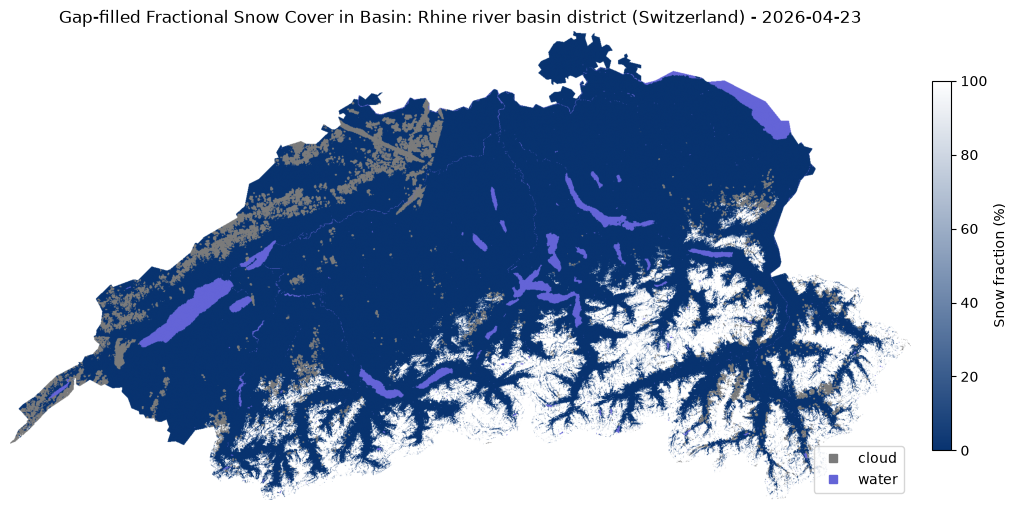

In [18]:
fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(snow_fraction_rgb(gf, gf_mask), extent=(bxmin, bxmax, bymin, bymax))
ax.set_title(
    f"Gap-filled Fractional Snow Cover in Basin: {basin_name} - {product_date}"
)
ax.set_axis_off()
add_snow_legend(ax)
plt.show()

## 5. Filter observations with quality layer information: sensor type

The Gap-filled GFSC product generates a continuous snow cover layer combining several inputs. The `QAFLAGS` band is a bit-encoded quality layer that records, among other things, where each pixel came from: **bit 7** is `0` for an **optical** observation (Sentinel-2) and `1` for a **radar** one (Sentinel-1). The full list of bit meanings is in the product user manual on the [CLMS snow portfolio page](https://land.copernicus.eu/en/products/snow).

> **Note on observation age.** The full HR-WSI product contains an `_AT` layer holding an acquisition timestamp per pixel, which can be used to work out how out of date each gap-filled pixel is. That layer is not part of the Sentinel Hub GFSC collection, which exposes `GF`, `GF_QA` and `QAFLAGS` only. If you need pixel age, download the product through the [OData API](../../geo/odata_clms_hr_water_snow_ice.ipynb).

In [19]:
qa_evalscript = """
//VERSION=3
function setup() {
  return {
    input: ["GF", "QAFLAGS", "dataMask"],
    output: { bands: 3, sampleType: "UINT8" }
  };
}
function evaluatePixel(sample) {
  return [sample.GF, sample.QAFLAGS, sample.dataMask];
}
"""

response = fetch(gfsc_collection, qa_evalscript, my_basin, product_date, BASIN_RES)
qa_gf, qaflags, qa_mask = response[..., 0], response[..., 1], response[..., 2]

# Extract bit 7 for sensor type (0 = optical observation, 1 = radar observation)
is_radar = (qaflags >> 7) & 1
has_value = (qa_gf <= 100) & (qa_mask > 0)

n_optical = int((has_value & (is_radar == 0)).sum())
n_radar = int((has_value & (is_radar == 1)).sum())
total = n_optical + n_radar

print(f"Snow-fraction pixels on {product_date}:")
print(f"  from Sentinel-2 (optical): {n_optical:,} ({100 * n_optical / total:.1f} %)")
print(f"  from Sentinel-1 (radar):   {n_radar:,} ({100 * n_radar / total:.1f} %)")

Snow-fraction pixels on 2026-04-23:
  from Sentinel-2 (optical): 957,079 (85.8 %)
  from Sentinel-1 (radar):   158,091 (14.2 %)


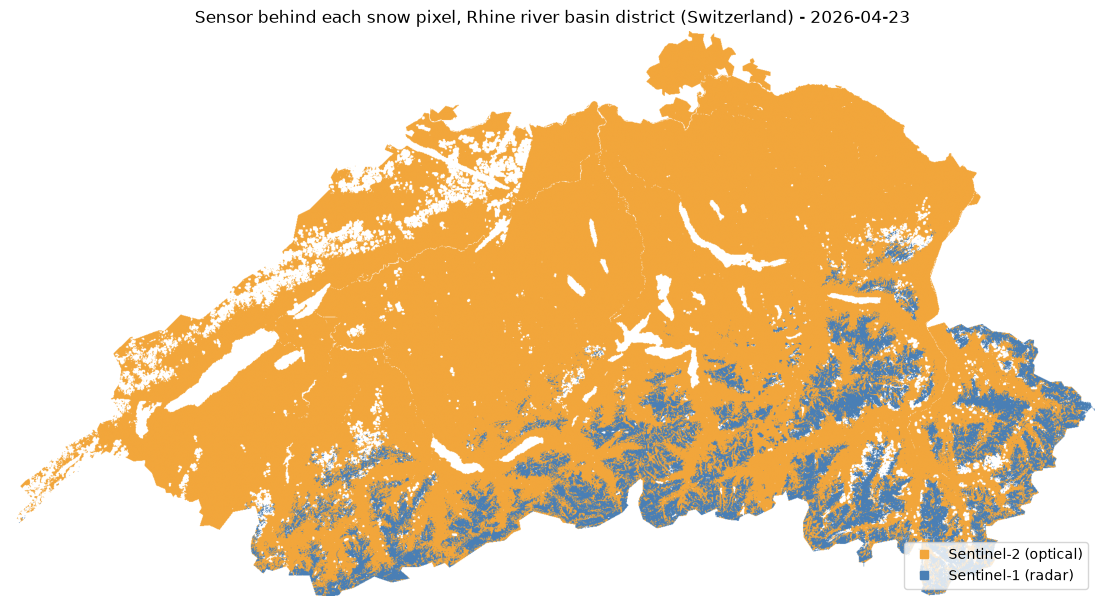

In [20]:
provenance = np.full(qa_gf.shape, np.nan)
provenance[has_value & (is_radar == 0)] = 0
provenance[has_value & (is_radar == 1)] = 1

provenance_cmap = ListedColormap(["#f2a63b", "#4a7fb5"])
provenance_cmap.set_bad(alpha=0)

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(
    provenance,
    cmap=provenance_cmap,
    vmin=-0.5,
    vmax=1.5,
    extent=(bxmin, bxmax, bymin, bymax),
)
ax.set_title(f"Sensor behind each snow pixel, {basin_name} - {product_date}")
ax.set_axis_off()
ax.legend(
    handles=[
        plt.Line2D(
            [],
            [],
            marker="s",
            linestyle="",
            color="#f2a63b",
            label="Sentinel-2 (optical)",
        ),
        plt.Line2D(
            [],
            [],
            marker="s",
            linestyle="",
            color="#4a7fb5",
            label="Sentinel-1 (radar)",
        ),
    ],
    loc="lower right",
)
plt.show()

## 6. Explore Snow Phenology (SPS2) products

Now let's retrieve and explore the **Snow Phenology** yearly product. It summarises a whole hydrological year into per-pixel dates and durations, derived from Sentinel-2:

| Band | Meaning |
|---|---|
| `SCD` | Snow Cover Duration — number of snow-covered days in the year |
| `SCO` | Snow Cover Onset — day of year when snow cover began |
| `SCM` | Snow Cover Melt-out — day of year when snow cover ended |

`65535` marks no data in all three.

These are yearly products, timestamped **1 September**, the start of the hydrological year, so a whole-calendar-year interval returns the product for that year. Not every year is available for every area — run the catalogue search first to see what exists before requesting pixels.

In [21]:
sps2_collection = DataCollection.define_byoc(
    HRWSI_snow_collection["SPS2"]["collection_id"], name="HRWSI_SPS2"
)

# SPS2 products are timestamped 1 September, the start of the hydrological year, so a
# whole-calendar-year interval picks up the product for that year.
phenology_year = 2018

phenology_evalscript = """
//VERSION=3
function setup() {
  return {
    input: ["SCD", "SCO", "SCM", "dataMask"],
    output: { bands: 4, sampleType: "UINT16" }
  };
}
function evaluatePixel(sample) {
  return [sample.SCD, sample.SCO, sample.SCM, sample.dataMask];
}
"""

print(
    f"Executing query for SPS2 products intersecting our selected basin ({phenology_year})..."
)
sps_results = execute_request(
    sps2_collection, my_basin, (f"{phenology_year}-01-01", f"{phenology_year}-12-31")
)

response = fetch(
    sps2_collection,
    phenology_evalscript,
    my_basin,
    f"{phenology_year}-01-01",
    BASIN_RES,
    end_date=f"{phenology_year}-12-31",
)
scd, sco, scm, phen_mask = (response[..., i] for i in range(4))

# Values above 366 are status codes rather than dates: 420 marks inland water, 65535 is
# no data. Only 0-366 carries a day count.
WATER_CODE = 420

in_basin = phen_mask > 0
is_water = in_basin & (scd == WATER_CODE)
valid_phen = in_basin & (scd <= 366)

print(f"\nSnow phenology {phenology_year}, {basin_name}")
print(f"  pixels with a day count: {int(valid_phen.sum()):,}")
print(f"  inland water (420):      {int(is_water.sum()):,}")
if valid_phen.any():
    print(f"  mean snow cover duration: {scd[valid_phen].mean():.0f} days")
    print(f"  max snow cover duration:  {scd[valid_phen].max():.0f} days")

Executing query for SPS2 products intersecting our selected basin (2018)...


Number of results: 9



Snow phenology 2018, Rhine river basin district (Switzerland)
  pixels with a day count: 602,182
  inland water (420):      43,678
  mean snow cover duration: 163 days
  max snow cover duration:  365 days


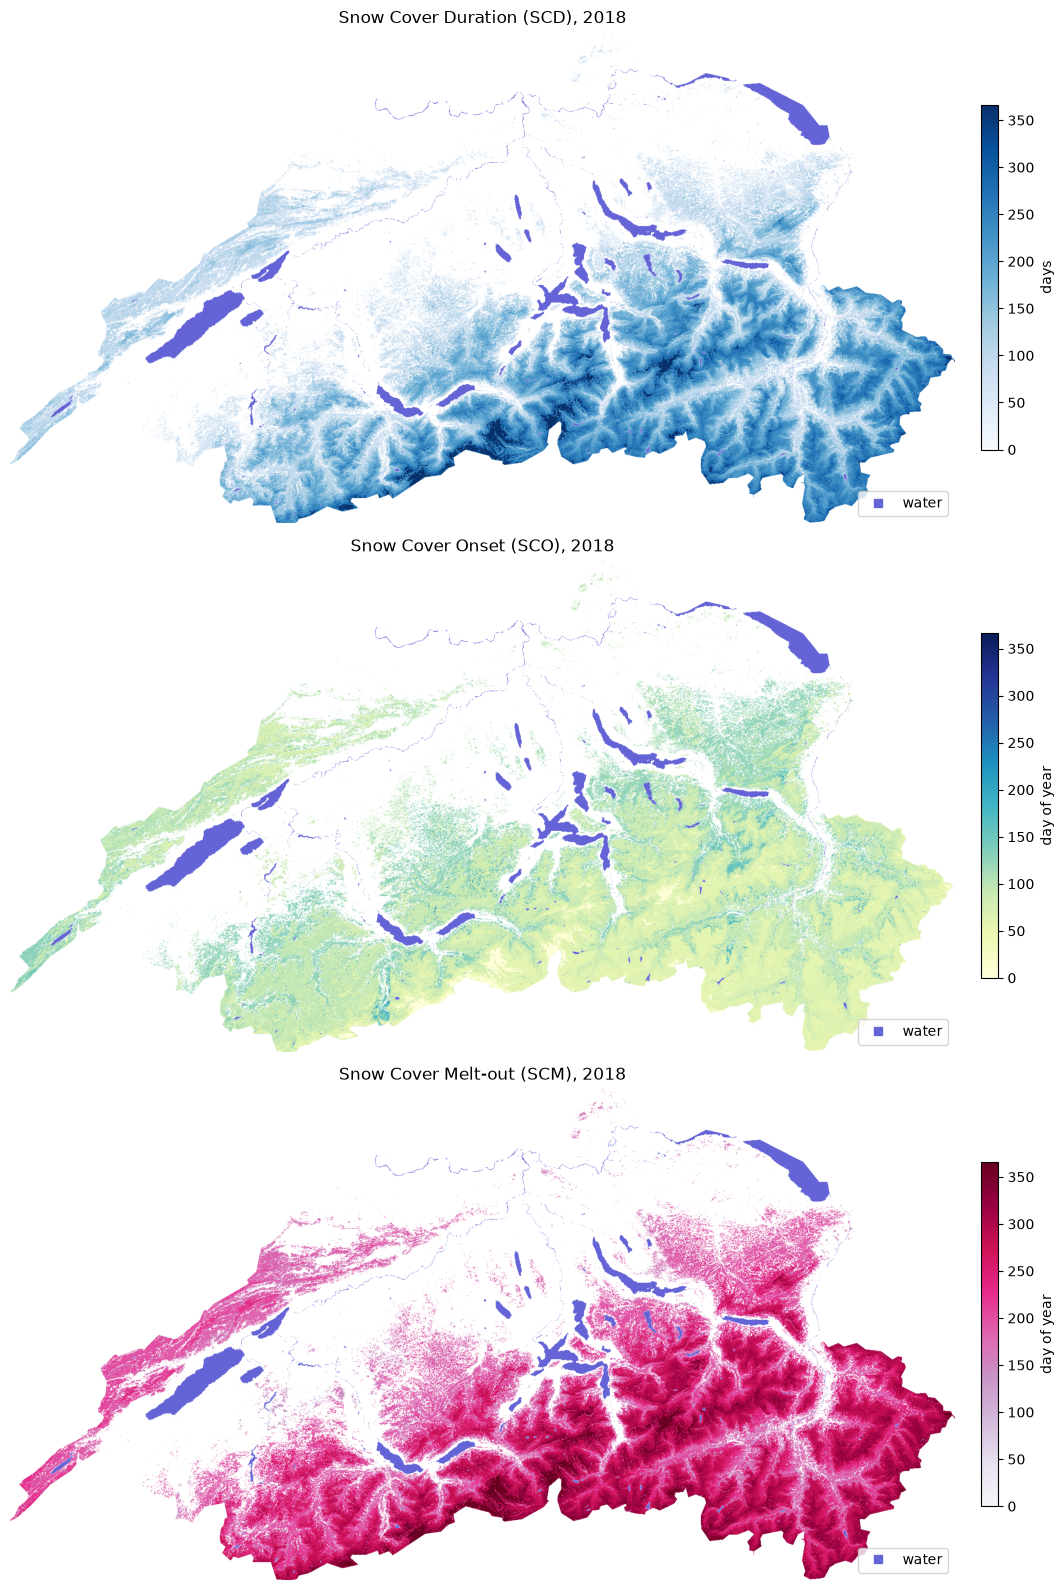

In [22]:
panels = [
    (scd, "Snow Cover Duration (SCD)", "days", "Blues"),
    (sco, "Snow Cover Onset (SCO)", "day of year", "YlGnBu"),
    (scm, "Snow Cover Melt-out (SCM)", "day of year", "PuRd"),
]

fig, axes = plt.subplots(3, 1, figsize=(13, 16))
for ax, (band, title, unit, cmap_name) in zip(axes, panels):
    display_band = np.where(valid_phen, band, np.nan).astype(float)
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad(alpha=0)
    image = ax.imshow(
        display_band,
        cmap=cmap,
        vmin=0,
        vmax=366,
        extent=(bxmin, bxmax, bymin, bymax),
    )

    # Draw the inland-water pixels on top, in the official water colour.
    water_layer = np.where(is_water, 1.0, np.nan)
    ax.imshow(
        water_layer,
        cmap=ListedColormap([WATER_COLOR]),
        vmin=0,
        vmax=1,
        extent=(bxmin, bxmax, bymin, bymax),
    )

    ax.set_title(f"{title}, {phenology_year}")
    ax.set_axis_off()
    fig.colorbar(image, ax=ax, shrink=0.7, pad=0.02, label=unit)
    ax.legend(
        handles=[
            plt.Line2D(
                [], [], marker="s", linestyle="", color=WATER_COLOR, label="water"
            )
        ],
        loc="lower right",
    )

plt.tight_layout()
plt.show()

## Where to go next

**Other HR-WSI collections.** Everything above works unchanged for the rest of the portfolio: swap the collection ID and the band names. `SWS` and `WDS` give wet-snow state from radar, `SPS1S2` extends phenology with Sentinel-1, and the water and ice products follow the same pattern. The full list with IDs is in the [CLMS collections documentation](https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Data/CLMS.html).

**Ready-made evalscripts.** The [CDSE custom scripts repository](https://github.com/eu-cdse/sentinel-hub-custom-scripts) holds visualisation scripts for each CLMS collection, using the official legends.

**When to use OData instead.** If you need whole products at native resolution for local processing, or you are building an archive, downloading through OData is the right tool. The [companion notebook](../../geo/odata_clms_hr_water_snow_ice.ipynb) covers that path.

### Further reading

- [Sentinel Hub APIs on CDSE](https://documentation.dataspace.copernicus.eu/APIs/SentinelHub.html)
- [Process API](https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Process.html)
- [Statistical API](https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Statistical.html)
- [Catalog API](https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Catalog.html)
- [CLMS snow portfolio](https://land.copernicus.eu/en/products/snow)
- [CLMS service helpdesk](https://land.copernicus.eu/en/contact-service-helpdesk)